# Nobel Laureates

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

### Read The Data File into a DataFrame

In [2]:
df = pd.read_csv(
    "nobel_laureates.csv",
    dtype={"id": "string", "award_year": "int"}
)

In [3]:
df.head(3)

,id,fullName,orgName,gender,birth_date,now_country,death_date,prize,award_year
0,745,A. Michael Spence,NaN,male,1943-11-07,USA,NaN,The Sveriges Riksbank Prize in Economic Scienc...,2001
1,102,Aage Niels Bohr,NaN,male,1922-06-19,Denmark,2009-09-08,The Nobel Prize in Physics,1975
2,779,Aaron Ciechanover,NaN,male,1947-10-01,Israel,NaN,The Nobel Prize in Chemistry,2004


### 1. Which prize category has the most laureate entries?

In [5]:
category_counts = df.groupby("prize").size().sort_values(ascending=False)
print("\n1. Laureate entries by prize category")
print(category_counts)


1. Laureate entries by prize category
prize
The Nobel Prize in Physiology or Medicine                                     235
The Nobel Prize in Physics                                                    231
The Nobel Prize in Chemistry                                                  202
The Nobel Peace Prize                                                         144
The Nobel Prize in Literature                                                 123
The Sveriges Riksbank Prize in Economic Sciences in Memory of Alfred Nobel    101
dtype: int64


### Chart: Category Counts

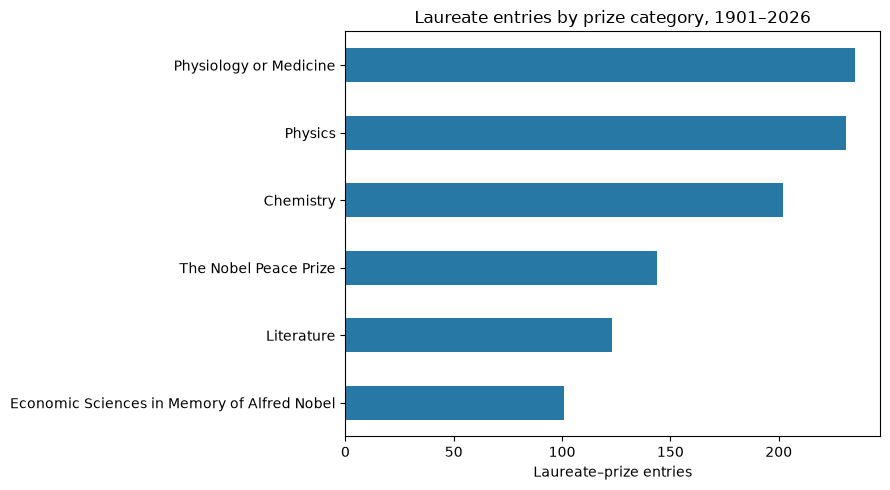

In [6]:
chart_counts = category_counts.sort_values()
chart_counts.index = (
    chart_counts.index
    .str.replace("The Nobel Prize in ", "", regex=False)
    .str.replace("The Sveriges Riksbank Prize in ", "", regex=False)
)

chart_counts.plot(kind="barh", figsize=(9, 5), color="#2878A5")
plt.title("Laureate entries by prize category, 1901–2026")
plt.xlabel("Laureate–prize entries")
plt.ylabel("")
plt.tight_layout()
plt.show()

### 2. Which award years had the most laureate entries?

In [7]:
year_counts = df.groupby("award_year").size().sort_values(ascending=False)
print("\n2. Top award years by laureate entries")
print(year_counts.head(10))


2. Top award years by laureate entries
award_year
2001    15
2022    14
2019    14
2025    14
2005    13
2000    13
2002    13
2011    13
1996    13
2013    13
dtype: int64


### 3. Which laureates received more than one prize?

In [8]:
multi_prize_ids = df["id"].value_counts()
multi_prize_ids = multi_prize_ids[multi_prize_ids > 1].index

multi_prize_winners = (
    df[df["id"].isin(multi_prize_ids)]
    .sort_values(["id", "award_year"])
    [["id", "fullName", "orgName", "prize", "award_year"]]
)
print("\n3. Laureates with multiple prizes")
print(multi_prize_winners.to_string(index=False))


3. Laureates with multiple prizes
 id                    fullName                                                     orgName                        prize  award_year
217          Linus Carl Pauling                                                         NaN The Nobel Prize in Chemistry        1954
217          Linus Carl Pauling                                                         NaN        The Nobel Peace Prize        1962
222            Frederick Sanger                                                         NaN The Nobel Prize in Chemistry        1958
222            Frederick Sanger                                                         NaN The Nobel Prize in Chemistry        1980
482                         NaN                    International Committee of the Red Cross        The Nobel Peace Prize        1917
482                         NaN                    International Committee of the Red Cross        The Nobel Peace Prize        1944
482                         NaN   

### 4. Which birth countries appear most often among individual laureates?

In [9]:
people = df[df["fullName"].notna()].drop_duplicates("id")
country_counts = (
    people.dropna(subset=["now_country"])
    .groupby("now_country")["id"]
    .nunique()
    .sort_values(ascending=False)
)
print("\n4. Individual laureates by birth country (current country label)")
print(country_counts.head(10))


4. Individual laureates by birth country (current country label)
now_country
USA                299
United Kingdom      94
Germany             86
France              64
Japan               31
Sweden              30
Russia              29
Poland              28
Canada              23
the Netherlands     20
Name: id, dtype: int64


### 5. How have laureate entries by category changed across decades?

In [10]:
df["decade"] = (df["award_year"] // 10) * 10
decade_counts = pd.crosstab(df["decade"], df["prize"])
print("\n5. Laureate entries by decade and prize category")
print(decade_counts)


5. Laureate entries by decade and prize category
prize   The Nobel Peace Prize  The Nobel Prize in Chemistry  \
decade                                                        
1900                       14                             9   
1910                        7                             8   
1920                       11                            10   
1930                        9                            13   
1940                        7                             9   
1950                        8                            14   
1960                        9                            15   
1970                       13                            15   
1980                       11                            21   
1990                       17                            18   
2000                       14                            25   
2010                       14                            27   
2020                       10                            18   

priz

### 6. laureate–prize entries by decade and category. The 2020s count runs through 2026.

prize   The Nobel Peace Prize  Chemistry  Literature  Physics  \
decade                                                          
1900s                      14          9          10       13   
1910s                       7          8           9       10   
1920s                      11         10          10       12   
1930s                       9         13           9       11   
1940s                       7          9           6        7   
1950s                       8         14          10       20   
1960s                       9         15          11       17   
1970s                      13         15          11       25   
1980s                      11         21          10       22   
1990s                      17         18          10       22   
2000s                      14         25          10       28   
2010s                      14         27          10       26   
2020s                      10         18           7       18   

prize   Physiology or Me

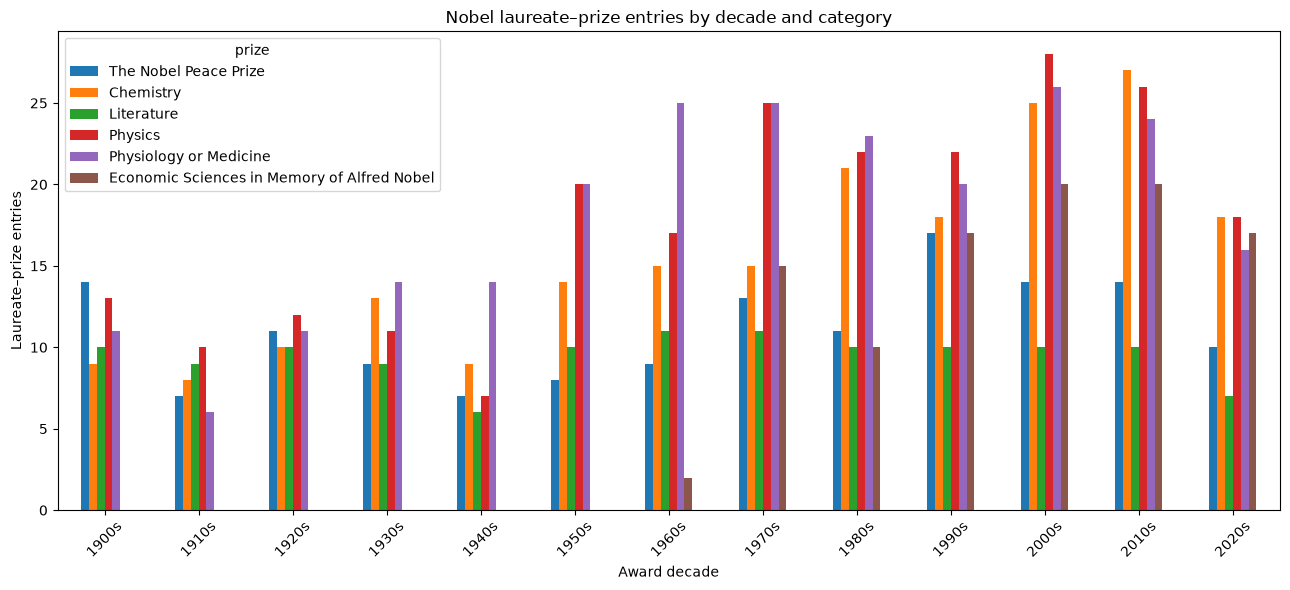

In [11]:
df = pd.read_csv("nobel_laureates.csv")
df["award_year"] = pd.to_numeric(df["award_year"])
df["decade"] = (df["award_year"] // 10) * 10

counts = pd.crosstab(df["decade"], df["prize"])

counts.columns = (
    counts.columns
    .str.replace("The Nobel Prize in ", "", regex=False)
    .str.replace("The Sveriges Riksbank Prize in ", "", regex=False)
)

counts.index = counts.index.astype(str) + "s"
print(counts)

counts.plot(kind="bar", figsize=(13, 6))
plt.title("Nobel laureate–prize entries by decade and category")
plt.xlabel("Award decade")
plt.ylabel("Laureate–prize entries")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()